# **Install Requirements**

In [1]:

import sys
import subprocess

# Install required packages
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "opencv-contrib-python-headless>=4.8,<5",
    "scikit-learn>=1.3",
    "matplotlib>=3.7",
    "pandas>=2",
    "tqdm>=4.66"
])

# Import libraries
import torch
import torchvision
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("GPU available:", torch.cuda.is_available())

assert (
    hasattr(cv2, "ximgproc")
    and hasattr(cv2.ximgproc, "segmentation")
), "Selective Search is unavailable. Check OpenCV installation."


PyTorch: 2.11.0+cu130
TorchVision: 0.26.0+cu130
OpenCV: 4.14.0
GPU available: True


# **Import Libraries and Set Configuration**

In [2]:

from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

import urllib.request
import zipfile
import random
import time
import os

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Dataset and model configuration
ROOT = Path("/content/rcnn_lab")
ROOT.mkdir(exist_ok=True, parents=True)

# Use a larger part of COCO128 than the original 40-image training subset.
MAX_TRAIN_IMAGES = 90
MAX_TEST_IMAGES = None       # None = use every image in the test split
MAX_PROPOSALS = 500          # More proposals improve the chance of covering objects
SIZE = 384

# ROI sampling limits help prevent a few images/classes from dominating training.
TRAIN_MAX_NEG = 60
TRAIN_MAX_POS_PER_CLASS = 40

# Detection settings. SVM margins are scores, NOT probabilities.
DETECTION_MARGIN = 0.5
NMS_IOU = 0.30

print("Configuration completed.")


Using device: cuda
GPU: Tesla T4
Configuration completed.


# **Download COCO128 Dataset**

In [3]:

URL = (
    "https://github.com/ultralytics/assets/"
    "releases/download/v0.0.0/coco128.zip"
)

archive = ROOT / "coco128.zip"

if not (ROOT / "coco128" / "images" / "train2017").exists():
    if not archive.exists():
        print("Downloading COCO128...")
        urllib.request.urlretrieve(URL, archive)

    print("Extracting dataset...")
    with zipfile.ZipFile(archive) as z:
        z.extractall(ROOT)

IMG_DIR = ROOT / "coco128" / "images" / "train2017"
LBL_DIR = ROOT / "coco128" / "labels" / "train2017"

# COCO category IDs used by this experiment:
# 0 = person, 2 = car, 16 = dog
COCO_CLASSES = {
    0: "person",
    2: "car",
    16: "dog"
}

def load_record(path):
    image = cv2.imread(str(path))
    if image is None:
        return None

    h, w = image.shape[:2]
    boxes = []
    label_path = LBL_DIR / (path.stem + ".txt")

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            vals = line.strip().split()
            if len(vals) != 5:
                continue

            cls = int(float(vals[0]))
            if cls not in COCO_CLASSES:
                continue

            xc, yc, bw, bh = map(float, vals[1:])
            x1 = max(0, (xc - bw / 2) * w)
            y1 = max(0, (yc - bh / 2) * h)
            x2 = min(w, (xc + bw / 2) * w)
            y2 = min(h, (yc + bh / 2) * h)

            if x2 > x1 and y2 > y1:
                boxes.append((
                    np.array([x1, y1, x2, y2], dtype=np.float32),
                    cls
                ))

    return {"path": path, "boxes": boxes}

records = [
    load_record(p)
    for p in sorted(IMG_DIR.glob("*"))
    if p.suffix.lower() in (".jpg", ".jpeg", ".png")
]
records = [r for r in records if r is not None and r["boxes"]]

print("Images with selected classes:", len(records))
object_counts = Counter(cls for record in records for _, cls in record["boxes"])
print("Object counts:", {COCO_CLASSES[k]: v for k, v in object_counts.items()})

assert len(records) >= 10, "Not enough labeled images. Check dataset extraction."

# Split by image to avoid putting regions from the same image in both sets.
train_records, test_records = train_test_split(
    records, test_size=0.25, random_state=SEED
)

train_records = train_records[:MAX_TRAIN_IMAGES]
if MAX_TEST_IMAGES is not None:
    test_records = test_records[:MAX_TEST_IMAGES]

print("Training images:", len(train_records))
print("Testing images:", len(test_records))
print("Training object counts:", {
    COCO_CLASSES[k]: v
    for k, v in Counter(
        cls for rec in train_records for _, cls in rec["boxes"]
    ).items()
})


Extracting dataset...
Images with selected classes: 75
Object counts: {'person': 254, 'dog': 9, 'car': 46}
Training images: 56
Testing images: 19
Training object counts: {'person': 166, 'dog': 8, 'car': 30}


# **Visualize Ground Truth Boxes**

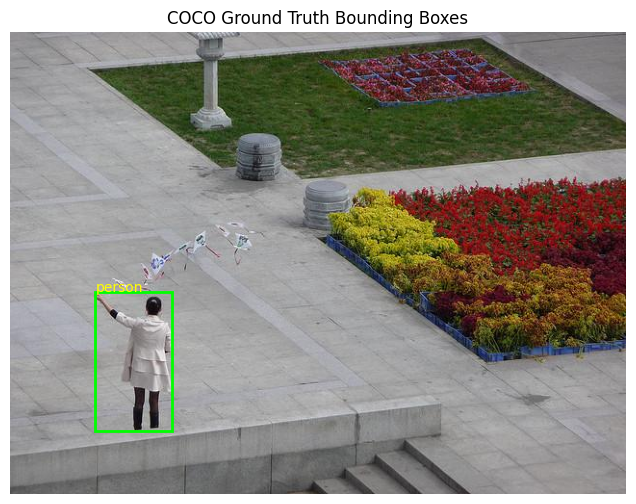

In [4]:

from matplotlib.patches import Rectangle

record = train_records[0]

image = cv2.cvtColor(
    cv2.imread(str(record["path"])),
    cv2.COLOR_BGR2RGB
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.imshow(image)

for box, cls in record["boxes"]:

    x1, y1, x2, y2 = box

    ax.add_patch(
        Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="lime",
            linewidth=2
        )
    )

    ax.text(
        x1,
        y1,
        COCO_CLASSES[cls],
        color="yellow",
        fontsize=10
    )

ax.set_title("COCO Ground Truth Bounding Boxes")
ax.axis("off")

plt.savefig(
    "/content/rcnn_lab/ground_truth.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# **Resize Images and Bounding Boxes**

In [5]:

def prepare_image(record):

    raw = cv2.cvtColor(
        cv2.imread(str(record["path"])),
        cv2.COLOR_BGR2RGB
    )

    h, w = raw.shape[:2]

    resized = cv2.resize(
        raw,
        (SIZE, SIZE)
    )

    gt = [
        (
            np.array([
                b[0] * SIZE / w,
                b[1] * SIZE / h,
                b[2] * SIZE / w,
                b[3] * SIZE / h
            ], dtype=np.float32),
            c
        )
        for b, c in record["boxes"]
    ]

    return resized, gt


sample, gt = prepare_image(train_records[0])

print("Resized image shape:", sample.shape)
print("Number of ground-truth boxes:", len(gt))


Resized image shape: (384, 384, 3)
Number of ground-truth boxes: 1


# **Selective Search Region Proposals**

In [6]:

def selective_proposals(image, limit=MAX_PROPOSALS):
    """Generate Selective Search proposals and remove invalid/duplicate boxes."""
    ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
    ss.setBaseImage(cv2.cvtColor(image, cv2.COLOR_RGB2BGR))
    ss.switchToSelectiveSearchFast()
    rects = ss.process()

    boxes = []
    seen = set()

    for x, y, w, h in rects:
        if w * h < 24 * 24 or w < 16 or h < 16:
            continue

        box = (
            int(max(0, x)),
            int(max(0, y)),
            int(min(x + w, SIZE)),
            int(min(y + h, SIZE))
        )

        if box not in seen and box[2] > box[0] and box[3] > box[1]:
            seen.add(box)
            boxes.append(box)

    # Keep a deterministic subset from the full Selective Search output.
    # This avoids stopping at the first 120 proposals, which can be biased
    # toward early/small regions returned by Selective Search.
    if len(boxes) > limit:
        step = len(boxes) / limit
        indices = np.floor(np.arange(limit) * step).astype(int)
        boxes = [boxes[i] for i in indices]

    return np.asarray(boxes, dtype=np.float32).reshape(-1, 4)


sample, gt = prepare_image(train_records[0])
start = time.perf_counter()
proposals = selective_proposals(sample)
proposal_time = time.perf_counter() - start

print("Number of proposals:", len(proposals))
print(f"Selective Search time: {proposal_time:.3f} seconds")


Number of proposals: 500
Selective Search time: 3.168 seconds


# **Visualize Region Proposals**

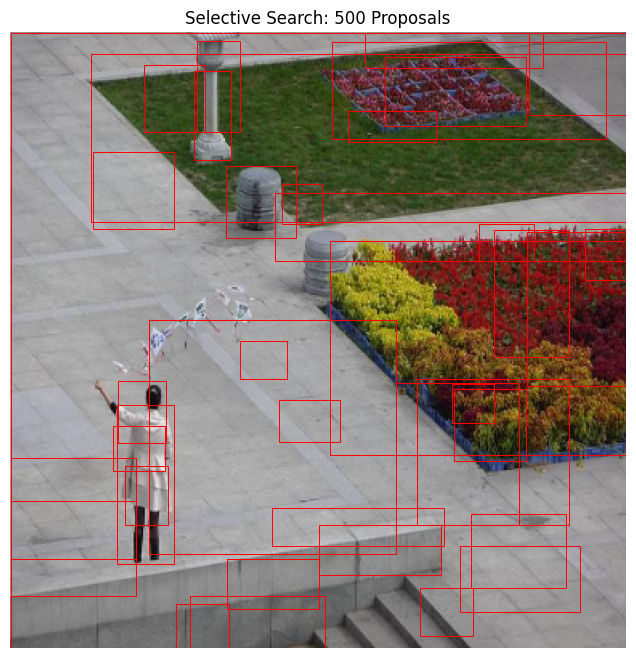

In [7]:

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(sample)

for x1, y1, x2, y2 in proposals[:40]:

    ax.add_patch(
        Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=0.7
        )
    )

ax.set_title(
    f"Selective Search: {len(proposals)} Proposals"
)

ax.axis("off")

plt.savefig(
    "/content/rcnn_lab/selective_search.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# **Intersection over Union (IoU)**

In [8]:

def iou(box_a, box_b):

    xa = max(box_a[0], box_b[0])
    ya = max(box_a[1], box_b[1])

    xb = min(box_a[2], box_b[2])
    yb = min(box_a[3], box_b[3])

    intersection = (
        max(0, xb - xa) *
        max(0, yb - ya)
    )

    area_a = (
        max(0, box_a[2] - box_a[0]) *
        max(0, box_a[3] - box_a[1])
    )

    area_b = (
        max(0, box_b[2] - box_b[0]) *
        max(0, box_b[3] - box_b[1])
    )

    union = area_a + area_b - intersection

    return float(
        intersection / max(union, 1e-8)
    )


if len(proposals) > 0 and len(gt) > 0:

    value = iou(
        proposals[0],
        gt[0][0]
    )

    print("IoU value:", round(value, 3))


IoU value: 0.038


# **Training Region Labeling**

In [9]:

BACKGROUND = -1

def label_proposal(box, gt):
    if not gt:
        return BACKGROUND

    matches = [(iou(box, gbox), cls) for gbox, cls in gt]
    best_iou, best_cls = max(matches, key=lambda item: item[0])

    if best_iou >= 0.5:
        return best_cls
    if best_iou < 0.2:
        return BACKGROUND
    return None  # Ignore ambiguous proposals.

def build_training_rois(records):
    patches = []
    labels = []

    for rec in tqdm(records, desc="Preparing training regions"):
        image, gt = prepare_image(rec)
        regions = selective_proposals(image)

        # Ground-truth boxes are included as positive training examples.
        for box, cls in gt:
            x1, y1, x2, y2 = np.round(box).astype(int)
            if x2 - x1 >= 8 and y2 - y1 >= 8:
                patches.append(image[y1:y2, x1:x2])
                labels.append(cls)

        positive_by_class = {cls: [] for cls in COCO_CLASSES}
        negatives = []

        for box in regions:
            cls = label_proposal(box, gt)
            if cls is None:
                continue

            x1, y1, x2, y2 = np.round(box).astype(int)
            if x2 - x1 < 8 or y2 - y1 < 8:
                continue

            roi = image[y1:y2, x1:x2]

            if cls == BACKGROUND:
                negatives.append(roi)
            else:
                positive_by_class[cls].append(roi)

        # Cap positives per class/image and negatives per image.
        # This reduces severe class/sample imbalance.
        for cls, rois in positive_by_class.items():
            random.shuffle(rois)
            for roi in rois[:TRAIN_MAX_POS_PER_CLASS]:
                patches.append(roi)
                labels.append(cls)

        random.shuffle(negatives)
        for roi in negatives[:TRAIN_MAX_NEG]:
            patches.append(roi)
            labels.append(BACKGROUND)

    return patches, np.asarray(labels, dtype=int)

train_patches, y_train = build_training_rois(train_records)

print("Training labels:", {
    (COCO_CLASSES[int(k)] if k != BACKGROUND else "background"): int(v)
    for k, v in Counter(y_train).items()
})

assert len(np.unique(y_train)) >= 2, "Training requires at least two classes."


Preparing training regions:   0%|          | 0/56 [00:00<?, ?it/s]

Training labels: {'person': 843, 'background': 3360, 'dog': 114, 'car': 29}


# **CNN Feature Extraction with ResNet18**

In [10]:

from PIL import Image

from torch.utils.data import DataLoader, Dataset
from torchvision import models

weights = models.ResNet18_Weights.DEFAULT

backbone = models.resnet18(
    weights=weights
)

# Remove final classification layer
backbone.fc = torch.nn.Identity()

backbone = backbone.to(device).eval()

preprocess = weights.transforms()


class ROIDataset(Dataset):

    def __init__(self, images):
        self.images = images

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):

        return preprocess(
            Image.fromarray(self.images[index])
        )


@torch.no_grad()
def extract_features(patches, batch_size=32):

    if not patches:

        return np.empty(
            (0, 512),
            dtype=np.float32
        )

    loader = DataLoader(
        ROIDataset(patches),
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    result = []

    for batch in tqdm(
        loader,
        desc="Extracting CNN features",
        leave=False
    ):

        features = backbone(
            batch.to(device)
        )

        result.append(
            features.cpu().numpy()
        )

    return np.concatenate(
        result,
        axis=0
    )


X_train = extract_features(train_patches)

print("Feature matrix shape:", X_train.shape)
print("Feature dimension:", X_train.shape[1])


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 177MB/s]


Extracting CNN features:   0%|          | 0/136 [00:00<?, ?it/s]

Feature matrix shape: (4346, 512)
Feature dimension: 512


# **Train Linear SVM Classifier**

In [11]:

from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

svm = make_pipeline(
    StandardScaler(),
    LinearSVC(
        class_weight="balanced",
        max_iter=12000,
        C=0.5,
        random_state=SEED
    )
)

svm.fit(X_train, y_train)

print("Learned classes:", svm.named_steps["linearsvc"].classes_)
print("Training classification report:")
print(classification_report(
    y_train,
    svm.predict(X_train),
    zero_division=0
))
print("Note: training scores are not a measure of generalization.")


Learned classes: [-1  0  2 16]
Training classification report:
              precision    recall  f1-score   support

          -1       1.00      0.99      1.00      3360
           0       0.98      1.00      0.99       843
           2       1.00      1.00      1.00        29
          16       1.00      1.00      1.00       114

    accuracy                           0.99      4346
   macro avg       0.99      1.00      1.00      4346
weighted avg       0.99      0.99      0.99      4346

Note: training scores are not a measure of generalization.


# **Non-Maximum Suppression (NMS)**

In [12]:

def nms(boxes, scores, threshold=0.30):

    if len(boxes) == 0:
        return []

    order = np.argsort(scores)[::-1]

    keep = []

    while len(order):

        i = order[0]

        keep.append(int(i))

        remaining = []

        for j in order[1:]:

            if iou(boxes[i], boxes[j]) < threshold:
                remaining.append(j)

        order = np.array(
            remaining,
            dtype=int
        )

    return keep


# **Run Object Detection**

Extracting CNN features:   0%|          | 0/16 [00:00<?, ?it/s]

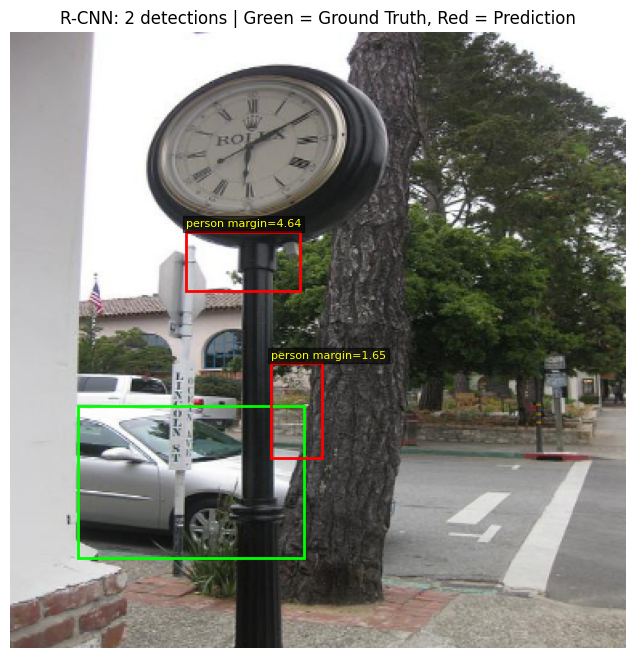

Total detections: 2


In [13]:

def detect(record, margin_threshold=DETECTION_MARGIN, nms_iou=NMS_IOU):
    image, gt = prepare_image(record)
    boxes = selective_proposals(image)

    patches = []
    valid = []

    for box in boxes:
        x1, y1, x2, y2 = np.round(box).astype(int)
        if x2 - x1 >= 8 and y2 - y1 >= 8:
            patches.append(image[y1:y2, x1:x2])
            valid.append(box)

    if not patches:
        return image, gt, []

    X = extract_features(patches)
    classifier = svm.named_steps["linearsvc"]
    classes = classifier.classes_
    predictions = svm.predict(X)
    margins = svm.decision_function(X)

    # LinearSVC uses one-vs-rest scores for multiclass classification.
    # Keep detections only for the class predicted for that proposal,
    # and apply a positive margin threshold to suppress weak predictions.
    if margins.ndim == 1:
        class_scores = np.column_stack((-margins, margins))
    else:
        class_scores = margins

    detections = []

    for class_index, cls in enumerate(classes):
        if cls == BACKGROUND:
            continue

        ids = [
            i for i in range(len(predictions))
            if predictions[i] == cls
            and class_scores[i, class_index] >= margin_threshold
        ]

        if not ids:
            continue

        class_boxes = np.asarray([valid[i] for i in ids], dtype=np.float32)
        scores = np.asarray(
            [class_scores[i, class_index] for i in ids],
            dtype=np.float32
        )

        selected = nms(class_boxes, scores, nms_iou)

        for j in selected:
            detections.append({
                "box": class_boxes[j],
                "class": int(cls),
                "score": float(scores[j])
            })

    return image, gt, detections


def show_detections(record, threshold=DETECTION_MARGIN):
    image, gt, detections = detect(record, margin_threshold=threshold)

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(image)

    # Ground-truth boxes are green; model predictions are red.
    for box, cls in gt:
        x1, y1, x2, y2 = box
        ax.add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor="lime", linewidth=2
        ))

    for item in detections:
        x1, y1, x2, y2 = item["box"]
        ax.add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor="red", linewidth=2
        ))
        ax.text(
            x1, max(0, y1 - 3),
            f'{COCO_CLASSES[item["class"]]} margin={item["score"]:.2f}',
            color="yellow", fontsize=8,
            bbox=dict(facecolor="black", alpha=0.55, pad=2)
        )

    ax.set_title(
        f"R-CNN: {len(detections)} detections | "
        "Green = Ground Truth, Red = Prediction"
    )
    ax.axis("off")
    plt.savefig(
        ROOT / "final_detections.png",
        dpi=200, bbox_inches="tight"
    )
    plt.show()
    return detections


predictions = show_detections(test_records[0])
print("Total detections:", len(predictions))


# **Evaluate Object Detection**

In [14]:

import pandas as pd

# Run detection on all test images
results = []

for rec in tqdm(test_records, desc="Evaluating test images"):

    _, gt, detections = detect(rec)

    results.append((gt, detections))


def evaluate_class(
    results,
    cls,
    iou_threshold=0.5
):

    # Ground-truth boxes for this class only
    gt_by_image = {
        i: [
            box for box, class_id in gt
            if class_id == cls
        ]
        for i, (gt, _) in enumerate(results)
    }

    total_gt = sum(
        len(boxes)
        for boxes in gt_by_image.values()
    )

    if total_gt == 0:
        return None

    # Collect predictions for this class
    ranked = []

    for image_id, (_, detections) in enumerate(results):

        for detection in detections:

            if detection["class"] == cls:

                ranked.append((
                    detection["score"],
                    image_id,
                    detection["box"]
                ))

    ranked.sort(
        key=lambda item: item[0],
        reverse=True
    )

    matched = {
        i: set()
        for i in gt_by_image
    }

    tp = []
    fp = []

    for score, image_id, box in ranked:

        gt_boxes = gt_by_image[image_id]

        matches = [
            iou(box, gt_box)
            if j not in matched[image_id]
            else -1

            for j, gt_box in enumerate(gt_boxes)
        ]

        j = int(np.argmax(matches)) if matches else -1

        good = (
            j >= 0
            and matches[j] >= iou_threshold
        )

        if good:

            matched[image_id].add(j)

        tp.append(int(good))
        fp.append(int(not good))

    if not tp:

        return {
            "class": COCO_CLASSES[cls],
            "gt": total_gt,
            "detections": 0,
            "precision": 0.0,
            "recall": 0.0,
            "AP50": 0.0
        }

    tp = np.cumsum(tp)
    fp = np.cumsum(fp)

    recall = tp / total_gt

    precision = tp / np.maximum(
        tp + fp,
        1
    )

    # Precision envelope
    r = np.r_[0.0, recall, 1.0]
    p = np.r_[0.0, precision, 0.0]

    for k in range(len(p) - 2, -1, -1):

        p[k] = max(
            p[k],
            p[k + 1]
        )

    changes = np.where(
        r[1:] != r[:-1]
    )[0]

    ap = float(
        np.sum(
            (r[changes + 1] - r[changes])
            * p[changes + 1]
        )
    )

    return {
        "class": COCO_CLASSES[cls],
        "gt": total_gt,
        "detections": len(ranked),
        "precision": float(precision[-1]),
        "recall": float(recall[-1]),
        "AP50": ap
    }


# Evaluate all represented test classes
rows = [
    evaluate_class(results, cls)
    for cls in COCO_CLASSES
]

# Exclude classes with no ground-truth objects in the test set
rows = [
    row for row in rows
    if row is not None
]

summary = pd.DataFrame(rows)

display(summary)

if len(summary) > 0:

    mean_ap = float(
        summary["AP50"].mean()
    )

    print(
        "mAP@0.5:",
        round(mean_ap, 3)
    )

else:

    print("No represented classes found in the test set.")


Evaluating test images:   0%|          | 0/19 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/16 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/16 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/16 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/16 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/16 [00:00<?, ?it/s]

... (12 outputs left out)

Extracting CNN features:   0%|          | 0/13 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/16 [00:00<?, ?it/s]

,class,gt,detections,precision,recall,AP50
0,person,88,277,0.061372,0.193182,0.06363
1,car,16,1,0.000000,0.000000,0.00000
2,dog,1,0,0.000000,0.000000,0.00000


mAP@0.5: 0.021


In [15]:

summary.to_csv(
    "/content/rcnn_lab/detection_evaluation.csv",
    index=False
)

print("Evaluation table saved successfully.")


Evaluation table saved successfully.


# **Visualize Precision and Recall**

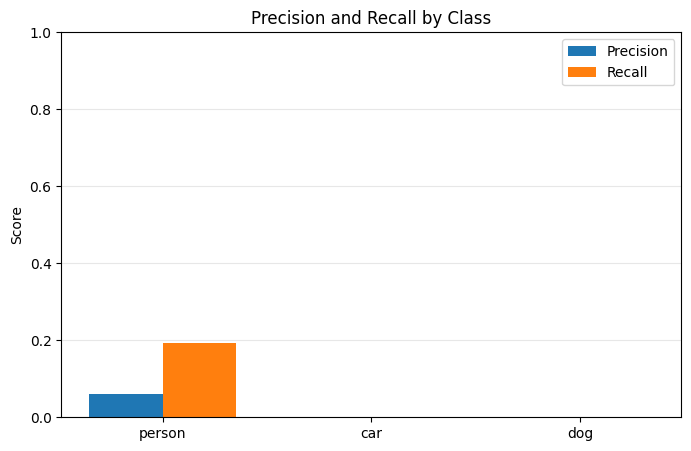

In [16]:

if len(summary) > 0:

    fig, ax = plt.subplots(figsize=(8, 5))

    x = np.arange(len(summary))
    width = 0.35

    ax.bar(
        x - width / 2,
        summary["precision"],
        width,
        label="Precision"
    )

    ax.bar(
        x + width / 2,
        summary["recall"],
        width,
        label="Recall"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(summary["class"])

    ax.set_ylim(0, 1)

    ax.set_ylabel("Score")
    ax.set_title("Precision and Recall by Class")

    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.savefig(
        "/content/rcnn_lab/precision_recall.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()


# **Final Results and Discussion**

### Experimental Results

The R-CNN pipeline was evaluated using a subset of the COCO128 dataset.

The experiment includes three object categories:
Person, Car, and Dog.

The system uses Selective Search for region proposals,
ResNet18 for CNN feature extraction, and Linear SVM
for region classification.

Non-Maximum Suppression is applied to reduce overlapping
detections.

The final performance is reported using Precision,
Recall, AP@0.5, and mAP@0.5.

# **Limitations**

- The experiment uses COCO128, a small subset of the full COCO dataset.
- Only three object categories are selected.
- The ResNet18 feature extractor is pretrained and frozen.
- The Linear SVM is trained on a limited number of region samples.
- Detection performance depends on Selective Search proposal quality.
- Learned bounding-box regression is not implemented.
- The test subset is small, so evaluation results may be unstable.
- SVM decision scores are margins, not calibrated probabilities.

This implementation is an educational R-CNN pipeline,
not a faithful reproduction of the original research paper.


##  Conclusion
In this laboratory, an educational implementation of the
original R-CNN detection pipeline was developed.

The experiment demonstrated how Selective Search generates
candidate regions, how a pretrained CNN extracts visual
features, and how a linear SVM classifies the proposed regions.

Non-Maximum Suppression was used to remove redundant
detections, while Precision, Recall, AP@0.5, and mAP@0.5
were used to evaluate detection performance.

The experiment also demonstrated the limitations of a
small dataset and the importance of region proposal quality
in object detection.

# **Checkpoint Questions and Answers**

Checkpoint 1 — Dataset
Q1. Why do we split by image rather than by region proposal?

We split by image to prevent data leakage. If proposals from the same image appear in both training and testing, the model may indirectly see similar visual information in both sets, producing unreliable evaluation results.

Q2. Why must bounding-box coordinates change when an image is resized?

Bounding-box coordinates must be scaled according to the image resizing factors. Otherwise, the boxes will no longer correctly surround the objects.

Q3. What limitations arise from selecting only a small subset of COCO?

A small subset contains fewer images and less visual diversity. Some classes may be underrepresented, and the evaluation results may be unstable and not representative of the complete COCO dataset.
Checkpoint 2 — Region Proposals
Q1. Why are there more proposals than actual objects?

Selective Search generates multiple candidate regions with different sizes and shapes because it does not know the actual number or locations of objects in advance.

Q2. What happens if a true object has no sufficiently overlapping proposal?

The detector cannot correctly detect that object because the classification stage cannot recover an object region that was not proposed. This limits the detector's recall.

Q3. How would image texture or lighting affect Selective Search?

Changes in texture, color, and lighting can affect region segmentation and merging, potentially producing inaccurate proposals or missing some objects.
Checkpoint 3 — CNN Features
Q1. Why is processing proposals independently expensive?

Each proposal is passed separately through the CNN. This repeats feature extraction operations many times and increases computational cost.

Q2. Why freeze the pretrained CNN in this lab?

The CNN is frozen to reduce training time and computational requirements while using visual features learned previously from ImageNet.

Q3. How does feature dimensionality affect classifier training?

Higher feature dimensionality increases memory and computational requirements. With a small dataset, it may also increase the risk of overfitting.
Checkpoint 4 — SVM
Q1. Why should random class labels never be used to demonstrate detector accuracy?

Random labels do not represent the actual objects. They prevent meaningful learning and produce misleading evaluation results.

Q2. What does class weighting do?

Class weighting helps address class imbalance by assigning different importance to classes during classifier training.

Q3. Why is training accuracy not a valid estimate of detection performance?

Training accuracy is measured on samples already used for learning. It may overestimate performance on unseen images. A separate test set is required.
Checkpoint 5 — Detection and NMS
Q1. Why must NMS use overlap between bounding boxes?

NMS uses bounding-box overlap to identify redundant detections that may represent the same object and retain the highest-scoring detection.

Q2. What changes when NMS IoU is reduced from 0.5 to 0.2?

NMS becomes more aggressive. More overlapping boxes are removed, which may eliminate duplicate detections but can also remove some valid boxes.

Q3. Why may detections remain poor even if the SVM trains successfully?

Detection quality also depends on proposal quality, feature representation, training data, localization accuracy, and score thresholds.
Checkpoint 6 — Evaluation
Q1. How does a localization error lower AP even if the class is correct?

If the predicted box does not reach IoU ≥ 0.5 with a ground-truth box, it is considered a false positive, reducing precision and AP.

Q2. Why is AP for a classification task different from object-detection AP?

Classification AP evaluates class predictions, while object-detection AP evaluates both the predicted class and bounding-box localization.

Q3. How does a small, imbalanced test subset affect reported mAP?

A small and imbalanced test set may produce unstable results and may not represent performance on a larger and more diverse dataset.
Final Checkpoint — Pipeline Understanding
Q1. Why does R-CNN require many CNN evaluations per image?

R-CNN processes each region proposal independently and passes every region through a CNN for feature extraction.

Q2. What is the role of the SVM after feature extraction?

The SVM classifies the extracted feature vectors into object categories or background.

Q3. Which R-CNN components are trained in this laboratory?

The Linear SVM classifier is trained. The ResNet18 feature extractor is pretrained and frozen, while Selective Search is not learned from the training data.

Q4. Which element of the original R-CNN architecture is omitted?

Learned bounding-box regression is omitted.

Q5. Explain how Selective Search recall limits final detector recall.

If Selective Search fails to generate a proposal that sufficiently overlaps a real object, the classifier cannot detect that object. Therefore, the proposal recall limits the maximum possible detector recall.

## Submission Files

In [17]:

from pathlib import Path
import shutil

submission_dir = Path("/content/rcnn_submission")
screenshots_dir = submission_dir / "screenshots"

screenshots_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Copy generated screenshots
files_to_copy = [
    "ground_truth.png",
    "selective_search.png",
    "final_detections.png",
    "precision_recall.png",
    "detection_evaluation.csv"
]

for filename in files_to_copy:

    source = Path("/content/rcnn_lab") / filename

    if source.exists():

        shutil.copy2(
            source,
            submission_dir / filename
        )

        print("Copied:", filename)

    else:

        print("Not found:", filename)

print("\nSubmission folder:", submission_dir)


Copied: ground_truth.png
Copied: selective_search.png
Copied: final_detections.png
Copied: precision_recall.png
Copied: detection_evaluation.csv

Submission folder: /content/rcnn_submission


In [18]:

import shutil

zip_path = shutil.make_archive(
    "/content/RCNN_Lab02_Results",
    "zip",
    root_dir="/content/rcnn_submission"
)

print("ZIP created:", zip_path)


ZIP created: /content/RCNN_Lab02_Results.zip


In [19]:

from google.colab import files

files.download(
    "/content/RCNN_Lab02_Results.zip"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>